In [78]:
import pandas as pd
import numpy as np

# Load the cleaned dataset
df = pd.read_csv("../data/processed/motor_cooling_cleaned.csv")

# Define input features
input_features = [
    "Coolant Flow Rate (LPH)",
    "Nanoparticle Concentration (%)",
    "Motor Speed (rpm)",
    "Motor Load (%)"
]

# Define output parameters
output_features = [
    "Winding Temperature (°C)",
    "Motor Efficiency (%)",
    "Cooling Efficiency (%)",
    "Casing Temp (°C)",
    "Pumping Power (W)"
]

# Separate inputs and outputs
X = df[input_features]
Y = df[output_features]

print("Input shape:", X.shape)
print("Output shape:", Y.shape)

Input shape: (108, 4)
Output shape: (108, 5)


In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 86
Testing samples: 22


In [80]:
from sklearn.preprocessing import StandardScaler

# Create scalers
X_scaler = StandardScaler()
Y_scaler = StandardScaler()

# Fit on training data only
X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

Y_train_scaled = Y_scaler.fit_transform(Y_train)
Y_test_scaled = Y_scaler.transform(Y_test)

print("Input scaling completed")
print("Output scaling completed")

Input scaling completed
Output scaling completed


In [81]:
from sklearn.neural_network import MLPRegressor

# Build ANN model
ann_model = MLPRegressor(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
    early_stopping=False
)

print("ANN model created successfully")

ANN model created successfully


In [82]:
# Select winding temperature
target = "Winding Temperature (°C)"

# Extract the target values
y_train = Y_train_scaled[:, Y.columns.get_loc(target)]

# Train ANN
ann_model.fit(X_train_scaled, y_train)

print("Winding temperature model trained successfully")

Winding temperature model trained successfully


In [83]:
# Predict using the trained ANN
y_pred_scaled = ann_model.predict(X_test_scaled)

# Convert predictions to original scale
y_pred = Y_scaler.inverse_transform(
    np.column_stack([
        np.zeros((len(y_pred_scaled), Y.shape[1]))
    ])
)

# Replace the relevant output column
target_index = Y.columns.get_loc(target)

y_pred[:, target_index] = Y_scaler.mean_[target_index] + (
    y_pred_scaled * Y_scaler.scale_[target_index]
)

# Display predictions
results = pd.DataFrame({
    "Actual Winding Temperature": Y_test[target].values,
    "Predicted Winding Temperature": y_pred[:, target_index]
})

display(results.head(10))

,Actual Winding Temperature,Predicted Winding Temperature
0,96.0,89.306045
1,110.5,107.451427
2,98.5,94.471293
3,108.0,102.372342
4,83.0,82.070012
5,90.5,88.484008
6,89.5,89.592407
7,102.5,99.084055
8,102.0,102.372342
9,115.0,111.215998


In [84]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(
    Y_test[target],
    y_pred[:, target_index]
)

mse = mean_squared_error(
    Y_test[target],
    y_pred[:, target_index]
)

rmse = np.sqrt(mse)

r2 = r2_score(
    Y_test[target],
    y_pred[:, target_index]
)

print("Target:", target)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Target: Winding Temperature (°C)
MAE: 3.3243198654437847
MSE: 15.354275668968102
RMSE: 3.918453224037273
R2 Score: 0.7821066843435008


In [85]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Store models and evaluation results
models = {}
evaluation_results = []

for target in output_features:

    print("\nTraining model for:", target)

    # Get the target column index
    target_index = Y.columns.get_loc(target)

    # Extract scaled training values
    y_train = Y_train_scaled[:, target_index]

    # Create ANN
    model = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred_scaled = model.predict(X_test_scaled)

    # Convert predictions to original units
    y_pred = (
        y_pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    # Actual values
    y_actual = Y_test[target].values

    # Calculate metrics
    mae = mean_absolute_error(y_actual, y_pred)
    mse = mean_squared_error(y_actual, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_pred)

    # Save model and results
    models[target] = model

    evaluation_results.append({
        "Target": target,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# Display results
evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)


Training model for: Winding Temperature (°C)

Training model for: Motor Efficiency (%)

Training model for: Cooling Efficiency (%)

Training model for: Casing Temp (°C)

Training model for: Pumping Power (W)


,Target,MAE,MSE,RMSE,R2
0,Winding Temperature (°C),3.324320,15.354276,3.918453,0.782107
1,Motor Efficiency (%),0.480039,0.324461,0.569615,0.899800
2,Cooling Efficiency (%),1.929119,4.963309,2.227849,0.817653
3,Casing Temp (°C),3.324320,15.354276,3.918453,0.782107
4,Pumping Power (W),0.676899,0.608509,0.780070,0.851010


In [86]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Store models and evaluation results
models = {}
evaluation_results = []

for target in output_features:

    print("\nTraining model for:", target)

    # Get the target column index
    target_index = Y.columns.get_loc(target)

    # Extract scaled training values
    y_train = Y_train_scaled[:, target_index]

    # Create ANN
    model = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred_scaled = model.predict(X_test_scaled)

    # Convert predictions to original units
    y_pred = (
        y_pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    # Actual values
    y_actual = Y_test[target].values

    # Calculate metrics
    mae = mean_absolute_error(y_actual, y_pred)
    mse = mean_squared_error(y_actual, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_pred)

    # Save model and results
    models[target] = model

    evaluation_results.append({
        "Target": target,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# Display results
evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)


Training model for: Winding Temperature (°C)

Training model for: Motor Efficiency (%)

Training model for: Cooling Efficiency (%)

Training model for: Casing Temp (°C)

Training model for: Pumping Power (W)


,Target,MAE,MSE,RMSE,R2
0,Winding Temperature (°C),3.324320,15.354276,3.918453,0.782107
1,Motor Efficiency (%),0.480039,0.324461,0.569615,0.899800
2,Cooling Efficiency (%),1.929119,4.963309,2.227849,0.817653
3,Casing Temp (°C),3.324320,15.354276,3.918453,0.782107
4,Pumping Power (W),0.676899,0.608509,0.780070,0.851010


In [87]:
architectures = {
    "1 Hidden Layer": (16,),
    "2 Hidden Layers": (16, 16),
    "3 Hidden Layers": (16, 16, 16),
    "4 Hidden Layers": (16, 16, 16, 16)
}

hidden_layer_results = []

target = "Winding Temperature (°C)"
target_index = Y.columns.get_loc(target)

y_train = Y_train_scaled[:, target_index]
y_test = Y_test[target].values

for name, architecture in architectures.items():

    model = MLPRegressor(
        hidden_layer_sizes=architecture,
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    pred_scaled = model.predict(X_test_scaled)

    pred = (
        pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    hidden_layer_results.append({
        "Architecture": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

hidden_layer_df = pd.DataFrame(hidden_layer_results)
display(hidden_layer_df)

,Architecture,MAE,RMSE,R2
0,1 Hidden Layer,3.324320,3.918453,0.782107
1,2 Hidden Layers,3.299427,3.790687,0.796084
2,3 Hidden Layers,3.319827,3.831877,0.791629
3,4 Hidden Layers,3.300876,3.755257,0.799878


In [88]:
neuron_values = [8, 16, 32, 64]

neuron_results = []

target = "Winding Temperature (°C)"
target_index = Y.columns.get_loc(target)

y_train = Y_train_scaled[:, target_index]
y_test = Y_test[target].values

for neurons in neuron_values:

    model = MLPRegressor(
        hidden_layer_sizes=(neurons,),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    pred_scaled = model.predict(X_test_scaled)

    pred = (
        pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    neuron_results.append({
        "Neurons": neurons,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

neuron_df = pd.DataFrame(neuron_results)
display(neuron_df)

,Neurons,MAE,RMSE,R2
0,8,3.417117,3.994201,0.773601
1,16,3.324320,3.918453,0.782107
2,32,3.155405,3.718122,0.803817
3,64,2.783126,3.226686,0.852250


In [89]:
activation_functions = [
    "relu",
    "tanh",
    "logistic",
    "identity"
]

activation_results = []

target = "Winding Temperature (°C)"
target_index = Y.columns.get_loc(target)

y_train = Y_train_scaled[:, target_index]
y_test = Y_test[target].values

for activation in activation_functions:

    model = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation=activation,
        solver="adam",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    pred_scaled = model.predict(X_test_scaled)

    pred = (
        pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    activation_results.append({
        "Activation": activation,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

activation_df = pd.DataFrame(activation_results)
display(activation_df)

,Activation,MAE,RMSE,R2
0,relu,3.324320,3.918453,0.782107
1,tanh,2.922130,3.613983,0.814652
2,logistic,3.100251,3.509637,0.825201
3,identity,2.824177,3.203028,0.854408


In [90]:
training_algorithms = ["adam", "sgd", "lbfgs"]

algorithm_results = []

target = "Winding Temperature (°C)"
target_index = Y.columns.get_loc(target)

y_train = Y_train_scaled[:, target_index]
y_test = Y_test[target].values

for algorithm in training_algorithms:

    model = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver=algorithm,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    pred_scaled = model.predict(X_test_scaled)

    pred = (
        pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    algorithm_results.append({
        "Algorithm": algorithm,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

algorithm_df = pd.DataFrame(algorithm_results)
display(algorithm_df)

,Algorithm,MAE,RMSE,R2
0,adam,3.324320,3.918453,0.782107
1,sgd,3.729083,4.232717,0.745755
2,lbfgs,4.255028,4.865469,0.664058


In [91]:
epoch_values = [100, 300, 500, 1000]

epoch_results = []

target = "Winding Temperature (°C)"
target_index = Y.columns.get_loc(target)

y_train = Y_train_scaled[:, target_index]
y_test = Y_test[target].values

for epochs in epoch_values:

    model = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver="adam",
        max_iter=epochs,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    pred_scaled = model.predict(X_test_scaled)

    pred = (
        pred_scaled * Y_scaler.scale_[target_index]
        + Y_scaler.mean_[target_index]
    )

    epoch_results.append({
        "Max Iterations": epochs,
        "Actual Iterations": model.n_iter_,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

epoch_df = pd.DataFrame(epoch_results)
display(epoch_df)

,Max Iterations,Actual Iterations,MAE,RMSE,R2
0,100,100,6.260350,7.304705,0.242784
1,300,300,3.598721,4.200487,0.749612
2,500,384,3.324320,3.918453,0.782107
3,1000,384,3.324320,3.918453,0.782107


In [92]:
import os

# Create results folder
os.makedirs("../experiments/results", exist_ok=True)

# Save experimental results
hidden_layer_df.to_csv(
    "../experiments/results/hidden_layer_results.csv",
    index=False
)

neuron_df.to_csv(
    "../experiments/results/neuron_results.csv",
    index=False
)

activation_df.to_csv(
    "../experiments/results/activation_results.csv",
    index=False
)

algorithm_df.to_csv(
    "../experiments/results/algorithm_results.csv",
    index=False
)

epoch_df.to_csv(
    "../experiments/results/epoch_results.csv",
    index=False
)

evaluation_df.to_csv(
    "../experiments/results/baseline_results.csv",
    index=False
)

print("All experimental results saved successfully!")

All experimental results saved successfully!


Effect of Number of Hidden Layers on ANN Performance

In [93]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Define ANN architectures
architectures = {
    "1 Hidden Layer": (16,),
    "2 Hidden Layers": (16, 16),
    "3 Hidden Layers": (16, 16, 16),
    "4 Hidden Layers": (16, 16, 16, 16)
}

# Create validation data from training data
X_tr, X_val, Y_tr, Y_val = train_test_split(
    X_train_scaled,
    Y_train_scaled,
    test_size=0.2,
    random_state=42
)

# Store results
hidden_layer_results = []

# Experiment with each output
for target in output_features:

    target_index = Y.columns.get_loc(target)

    y_train = Y_tr[:, target_index]
    y_val = Y_val[:, target_index]

    for name, architecture in architectures.items():

        model = MLPRegressor(
            hidden_layer_sizes=architecture,
            activation="relu",
            solver="adam",
            max_iter=1000,
            random_state=42
        )

        # Train model
        model.fit(X_tr, y_train)

        # Predict
        pred_scaled = model.predict(X_val)

        # Convert predictions to original units
        pred = (
            pred_scaled * Y_scaler.scale_[target_index]
            + Y_scaler.mean_[target_index]
        )

        actual = (
            y_val * Y_scaler.scale_[target_index]
            + Y_scaler.mean_[target_index]
        )

        # Evaluate
        hidden_layer_results.append({
            "Target": target,
            "Architecture": name,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)
        })

# Display results
hidden_layer_df = pd.DataFrame(hidden_layer_results)

display(hidden_layer_df)

,Target,Architecture,MAE,RMSE,R2
0,Winding Temperature (°C),1 Hidden Layer,3.140400,3.898832,0.883711
1,Winding Temperature (°C),2 Hidden Layers,2.424950,2.927727,0.934426
2,Winding Temperature (°C),3 Hidden Layers,2.389363,2.941215,0.933821
3,Winding Temperature (°C),4 Hidden Layers,2.391810,3.108820,0.926063
4,Motor Efficiency (%),1 Hidden Layer,0.406690,0.477512,0.952715
5,Motor Efficiency (%),2 Hidden Layers,0.544373,0.644024,0.913988
6,Motor Efficiency (%),3 Hidden Layers,0.464490,0.556969,0.935670
7,Motor Efficiency (%),4 Hidden Layers,0.509243,0.598142,0.925807
8,Cooling Efficiency (%),1 Hidden Layer,1.387248,1.683041,0.933306
9,Cooling Efficiency (%),2 Hidden Layers,1.664527,1.958693,0.909671


In [94]:
import os

os.makedirs("../experiments/results", exist_ok=True)

hidden_layer_df.to_csv(
    "../experiments/results/hidden_layer_results.csv",
    index=False
)

print("Hidden layer experiment completed and saved!")

Hidden layer experiment completed and saved!


Effect of Number of Neurons on ANN Performance

In [95]:
# Effect of Number of Neurons

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Different numbers of neurons
neuron_values = [8, 16, 32, 64]

# Store experimental results
neuron_results = []

# Use the same validation data as the previous experiment
for target in output_features:

    target_index = Y.columns.get_loc(target)

    y_train = Y_tr[:, target_index]
    y_val = Y_val[:, target_index]

    for neurons in neuron_values:

        # Build ANN
        model = MLPRegressor(
            hidden_layer_sizes=(neurons,),
            activation="relu",
            solver="adam",
            max_iter=1000,
            random_state=42
        )

        # Train model
        model.fit(X_tr, y_train)

        # Make predictions
        pred_scaled = model.predict(X_val)

        # Convert to original units
        pred = (
            pred_scaled * Y_scaler.scale_[target_index]
            + Y_scaler.mean_[target_index]
        )

        actual = (
            y_val * Y_scaler.scale_[target_index]
            + Y_scaler.mean_[target_index]
        )

        # Calculate evaluation metrics
        mae = mean_absolute_error(actual, pred)
        mse = mean_squared_error(actual, pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(actual, pred)

        # Store results
        neuron_results.append({
            "Target": target,
            "Neurons": neurons,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2
        })

# Convert results to DataFrame
neuron_df = pd.DataFrame(neuron_results)

display(neuron_df)

,Target,Neurons,MAE,MSE,RMSE,R2
0,Winding Temperature (°C),8,2.928175,14.282772,3.779255,0.890735
1,Winding Temperature (°C),16,3.140400,15.200891,3.898832,0.883711
2,Winding Temperature (°C),32,2.641530,10.034426,3.167716,0.923235
3,Winding Temperature (°C),64,1.996323,7.375029,2.715701,0.943580
4,Motor Efficiency (%),8,0.432833,0.285946,0.534739,0.940702
5,Motor Efficiency (%),16,0.406690,0.228017,0.477512,0.952715
6,Motor Efficiency (%),32,0.354348,0.190307,0.436242,0.960535
7,Motor Efficiency (%),64,0.403896,0.231792,0.481448,0.951933
8,Cooling Efficiency (%),8,1.427864,3.756989,1.938295,0.911542
9,Cooling Efficiency (%),16,1.387248,2.832628,1.683041,0.933306


In [96]:
import os

os.makedirs("../experiments/results", exist_ok=True)

neuron_df.to_csv(
    "../experiments/results/neuron_results.csv",
    index=False
)

print("Neuron experiment completed and saved!")

Neuron experiment completed and saved!


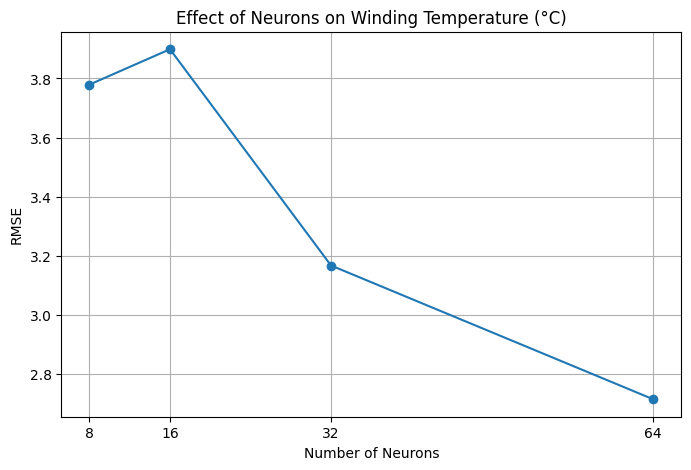

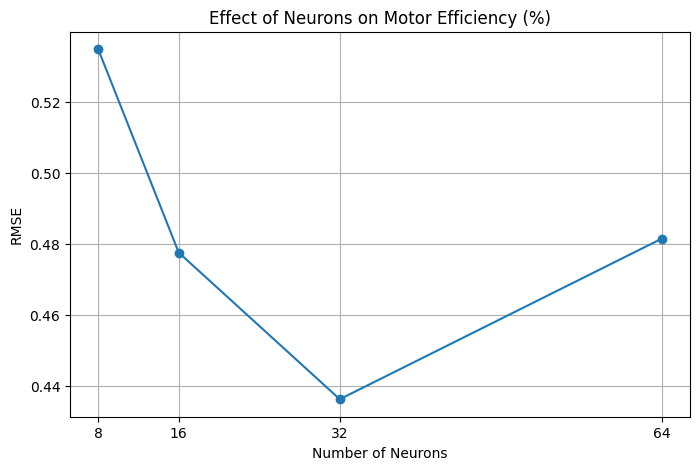

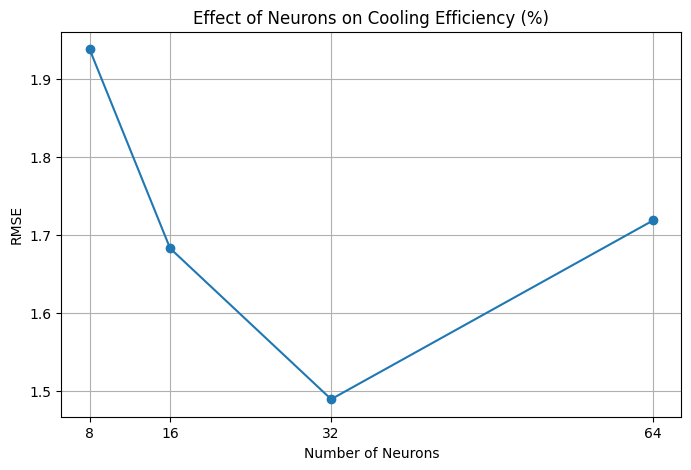

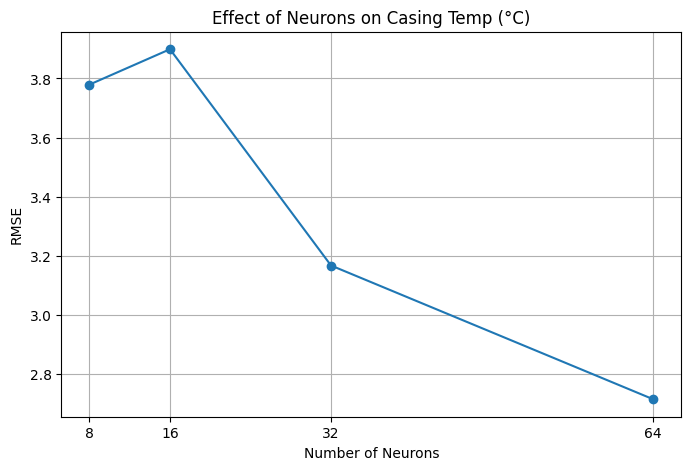

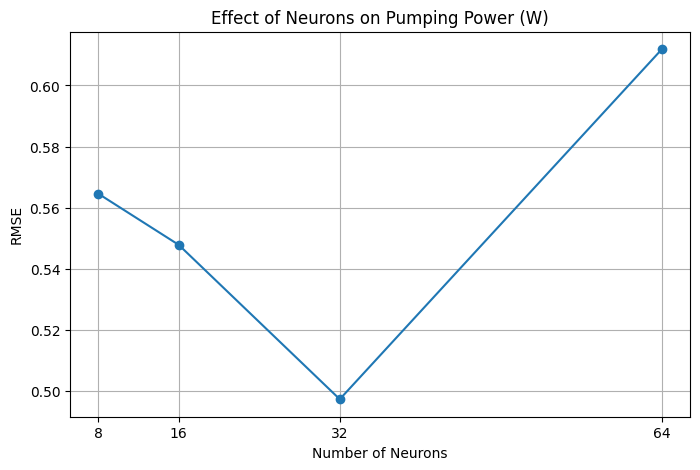

In [97]:
import matplotlib.pyplot as plt

for target in output_features:

    data = neuron_df[neuron_df["Target"] == target]

    plt.figure(figsize=(8, 5))

    plt.plot(
        data["Neurons"],
        data["RMSE"],
        marker="o"
    )

    plt.xlabel("Number of Neurons")
    plt.ylabel("RMSE")
    plt.title(f"Effect of Neurons on {target}")
    plt.xticks([8, 16, 32, 64])
    plt.grid(True)
    plt.show()

Effect of Activation Functions on ANN Performance.

In [98]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [99]:
activations = ["relu", "tanh", "logistic", "identity"]

print("Activation functions:", activations)

Activation functions: ['relu', 'tanh', 'logistic', 'identity']


In [100]:
activation_results = []

# Use the same architecture for every activation
hidden_layers = (2,)
neurons = 32

for target in Y_train.columns:

    for activation in activations:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ann", MLPRegressor(
                hidden_layer_sizes=(neurons, neurons),
                activation=activation,
                solver="adam",
                max_iter=1000,
                random_state=42
            ))
        ])

        model.fit(X_train, Y_train[target])

        predictions = model.predict(X_test)

        rmse = np.sqrt(
            mean_squared_error(Y_test[target], predictions)
        )

        r2 = r2_score(Y_test[target], predictions)

        activation_results.append({
            "Target": target,
            "Activation": activation,
            "RMSE": rmse,
            "R2": r2
        })

activation_df = pd.DataFrame(activation_results)

display(activation_df)

,Target,Activation,RMSE,R2
0,Winding Temperature (°C),relu,8.651454,-0.062167
1,Winding Temperature (°C),tanh,55.955984,-43.433206
2,Winding Temperature (°C),logistic,64.531646,-58.096269
3,Winding Temperature (°C),identity,2.977276,0.874208
4,Motor Efficiency (%),relu,8.148758,-19.506425
5,Motor Efficiency (%),tanh,47.403207,-692.940983
6,Motor Efficiency (%),logistic,55.966026,-966.288498
7,Motor Efficiency (%),identity,0.469918,0.931805
8,Cooling Efficiency (%),relu,4.883439,0.123848
9,Cooling Efficiency (%),tanh,13.875186,-6.073027


In [101]:
import os

os.makedirs("../experiments/results", exist_ok=True)

activation_df.to_csv(
    "../experiments/results/activation_results.csv",
    index=False
)

print("Activation function results saved successfully!")

Activation function results saved successfully!


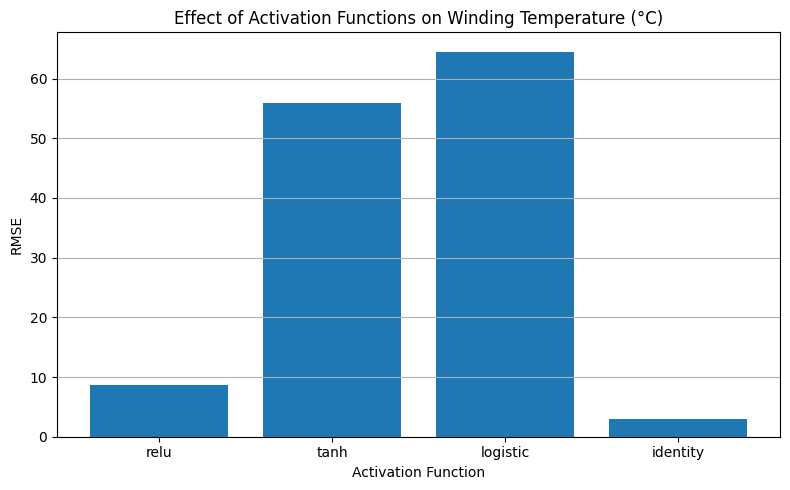

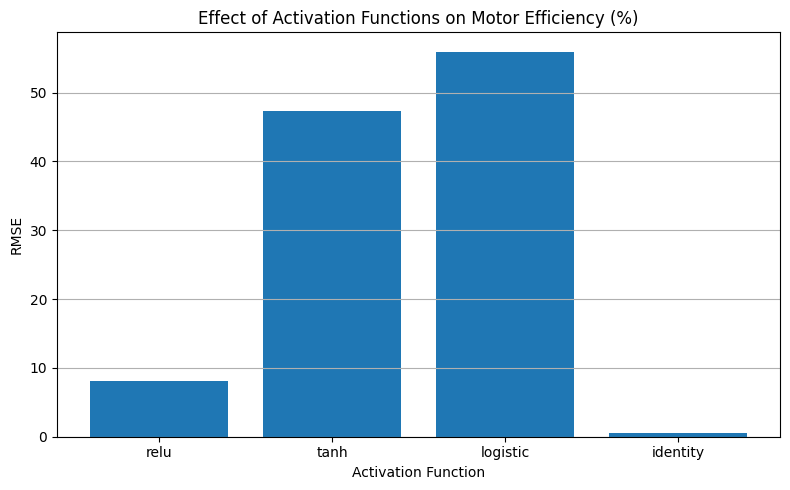

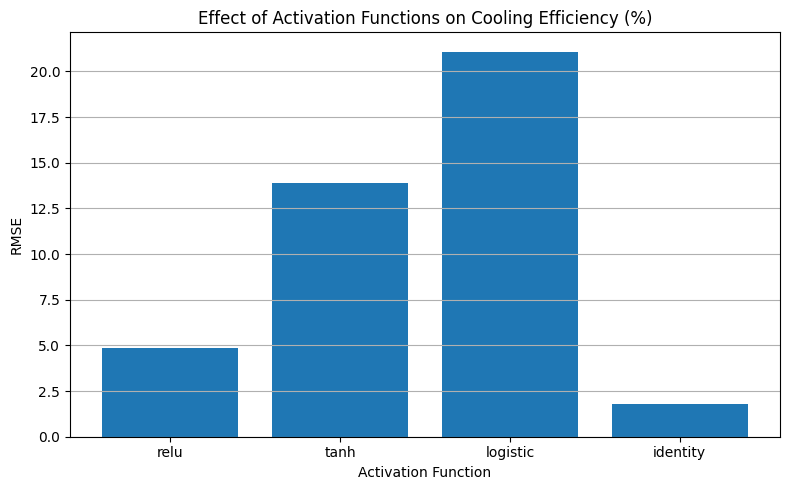

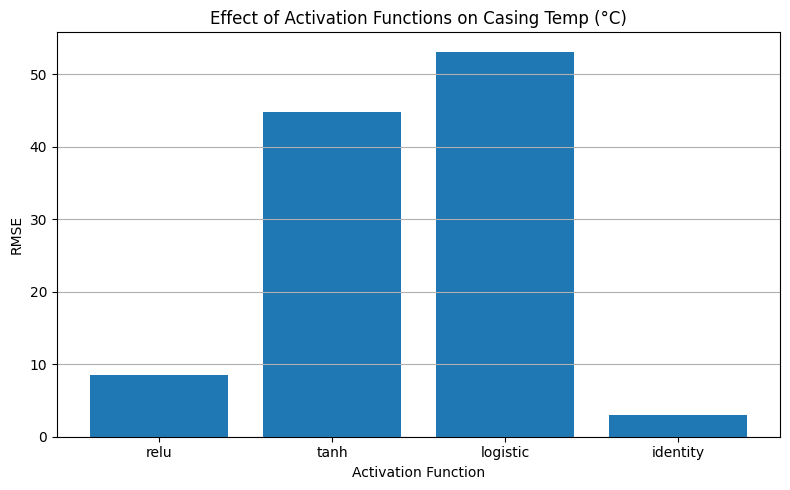

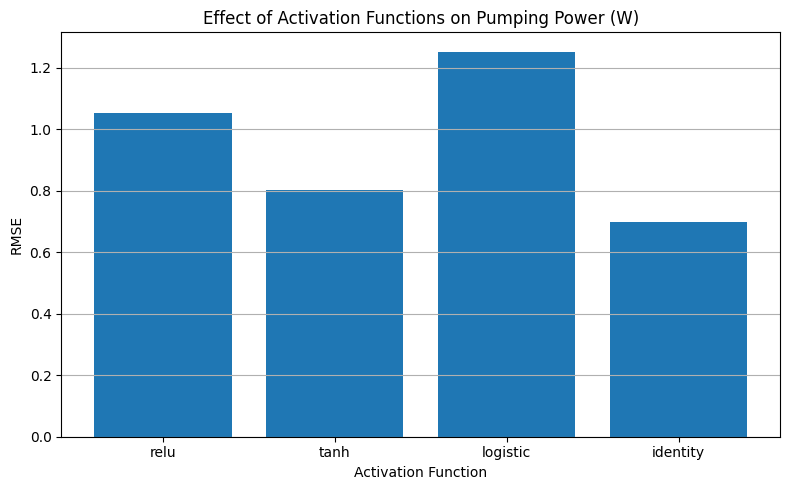

In [102]:
for target in activation_df["Target"].unique():

    data = activation_df[
        activation_df["Target"] == target
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(data["Activation"], data["RMSE"])

    plt.title(f"Effect of Activation Functions on {target}")
    plt.xlabel("Activation Function")
    plt.ylabel("RMSE")
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

Experiment 4: Effect of Training Algorithms on ANN Performance

Objective:
To investigate the effect of different training algorithms (Adam, SGD, and L-BFGS) on the prediction performance of an Artificial Neural Network (ANN) for motor cooling system parameters.
The performance of each algorithm will be evaluated using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), R² Score, and training time.

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [104]:
training_algorithms = ["adam", "sgd", "lbfgs"]

hidden_layers = (32, 32)
activation_function = "relu"

print("Training Algorithms:", training_algorithms)
print("Hidden Layers:", hidden_layers)
print("Activation Function:", activation_function)

Training Algorithms: ['adam', 'sgd', 'lbfgs']
Hidden Layers: (32, 32)
Activation Function: relu


In [105]:
# Experiment 4: Effect of Training Algorithms on ANN Performance

results = []

# Scale input features
X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

training_algorithms = ["adam", "sgd", "lbfgs"]

hidden_layers = (32, 32)
activation_function = "relu"

for target in Y_train.columns:

    # Scale the target variable
    y_scaler = StandardScaler()

    y_train_scaled = y_scaler.fit_transform(
        Y_train[[target]]
    ).ravel()

    y_test = Y_test[target].values

    for algorithm in training_algorithms:

        # Initialize ANN
        model = MLPRegressor(
            hidden_layer_sizes=hidden_layers,
            activation=activation_function,
            solver=algorithm,
            max_iter=2000,
            learning_rate_init=0.001,
            random_state=42,
            tol=1e-4
        )

        # Train the model
        start_time = time.time()

        model.fit(X_train_scaled, y_train_scaled)

        training_time = time.time() - start_time

        # Predict on test data
        predictions_scaled = model.predict(X_test_scaled)

        # Convert predictions to original units
        predictions = y_scaler.inverse_transform(
            predictions_scaled.reshape(-1, 1)
        ).ravel()

        # Calculate evaluation metrics
        rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )

        mae = mean_absolute_error(
            y_test, predictions
        )

        r2 = r2_score(
            y_test, predictions
        )

        # Store results
        results.append({
            "Target": target,
            "Training Algorithm": algorithm,
            "RMSE": rmse,
            "MAE": mae,
            "R2 Score": r2,
            "Training Time (s)": training_time
        })

# Create results DataFrame
algorithm_results = pd.DataFrame(results)

display(algorithm_results)

,Target,Training Algorithm,RMSE,MAE,R2 Score,Training Time (s)
0,Winding Temperature (°C),adam,3.679487,3.243937,0.807873,0.032823
1,Winding Temperature (°C),sgd,3.972923,3.367924,0.776007,0.024727
2,Winding Temperature (°C),lbfgs,4.993134,4.353986,0.646197,0.015566
3,Motor Efficiency (%),adam,0.580475,0.505906,0.895942,0.011918
4,Motor Efficiency (%),sgd,0.623098,0.507137,0.880100,0.021392
5,Motor Efficiency (%),lbfgs,0.759744,0.673874,0.821745,0.011832
6,Cooling Efficiency (%),adam,2.298490,2.003936,0.805906,0.011011
7,Cooling Efficiency (%),sgd,2.190985,1.863663,0.823637,0.019569
8,Cooling Efficiency (%),lbfgs,2.837403,2.428958,0.704219,0.012731
9,Casing Temp (°C),adam,3.679487,3.243937,0.807873,0.012473


In [106]:
import os

os.makedirs("../experiments/results", exist_ok=True)

algorithm_results.to_csv(
    "../experiments/results/training_algorithm_results.csv",
    index=False
)

print("Training algorithm results saved successfully!")

Training algorithm results saved successfully!


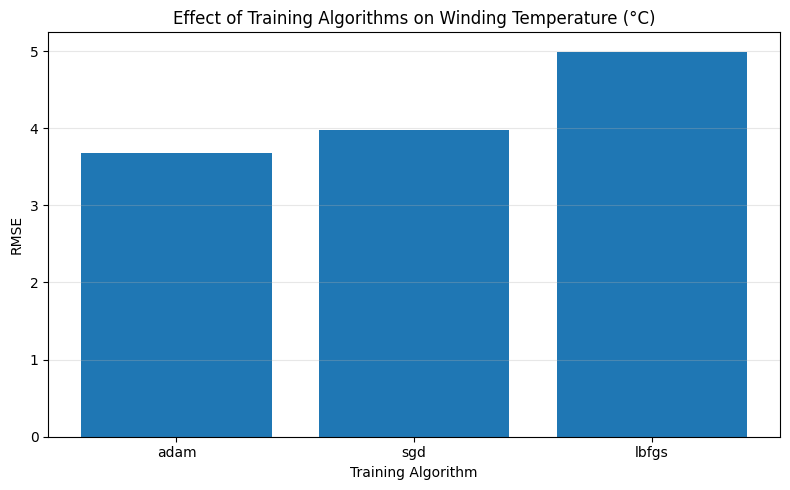

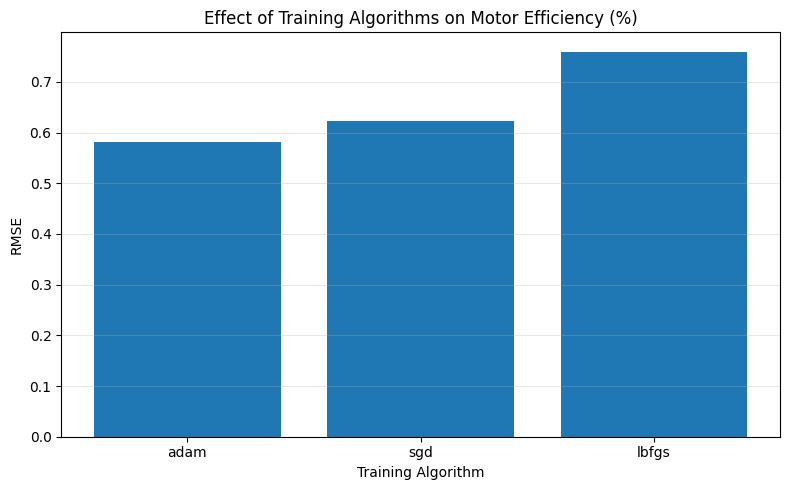

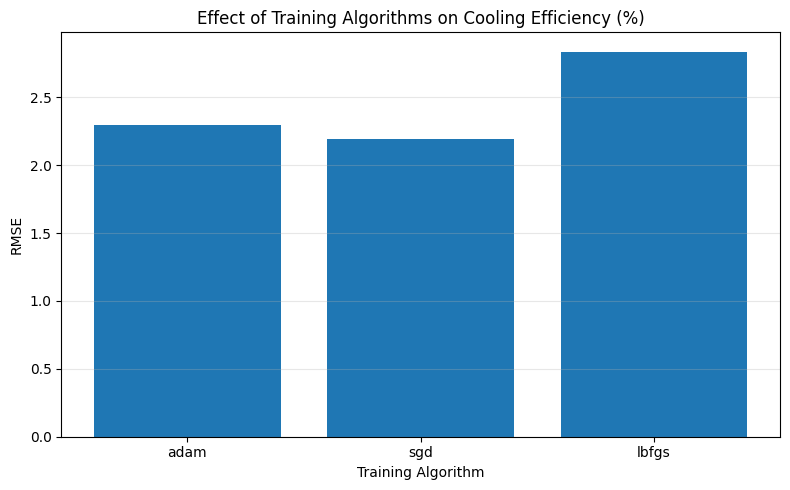

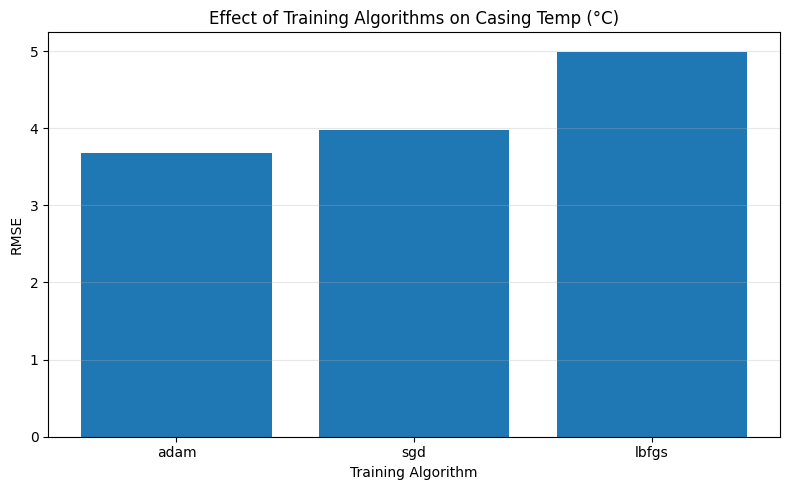

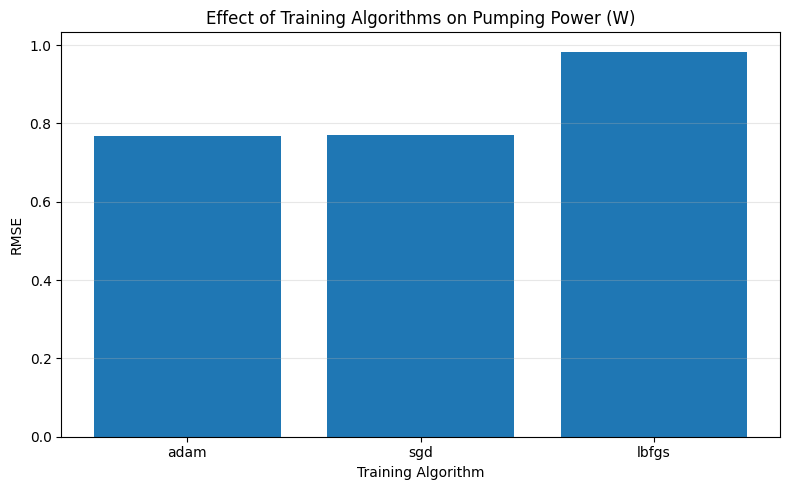

In [107]:
for target in algorithm_results["Target"].unique():

    data = algorithm_results[
        algorithm_results["Target"] == target
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        data["Training Algorithm"],
        data["RMSE"]
    )

    plt.title(f"Effect of Training Algorithms on {target}")
    plt.xlabel("Training Algorithm")
    plt.ylabel("RMSE")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

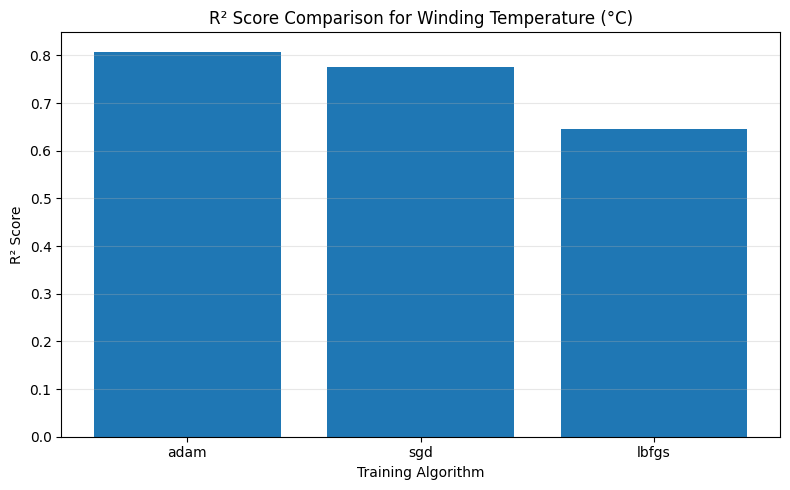

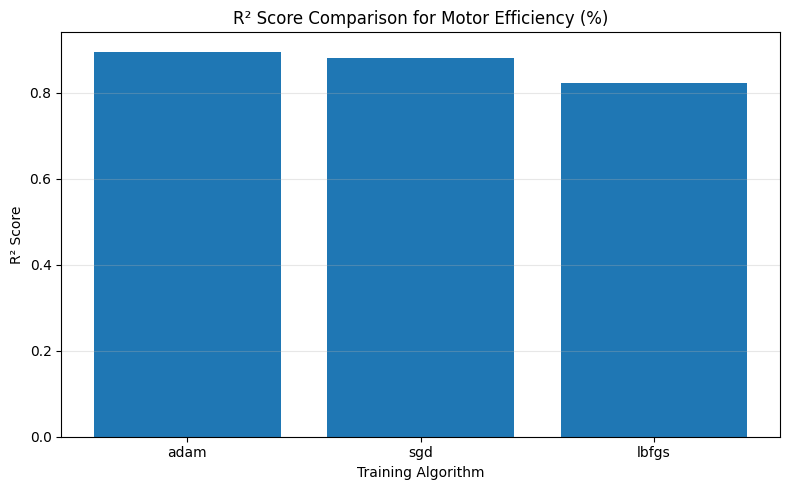

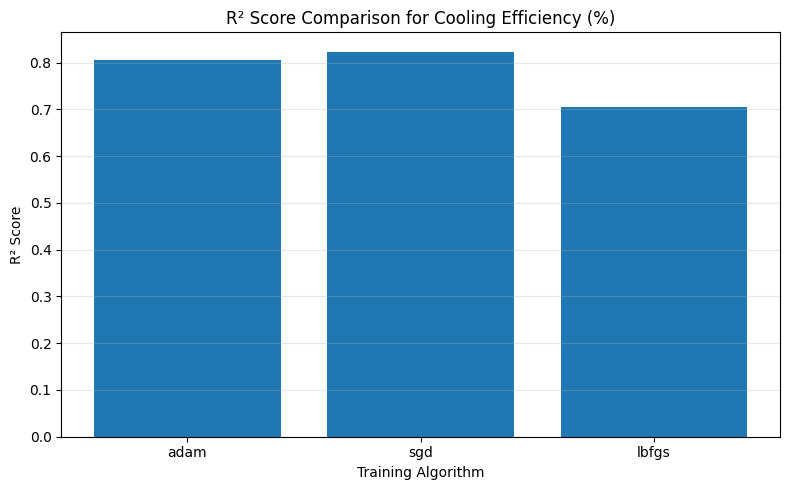

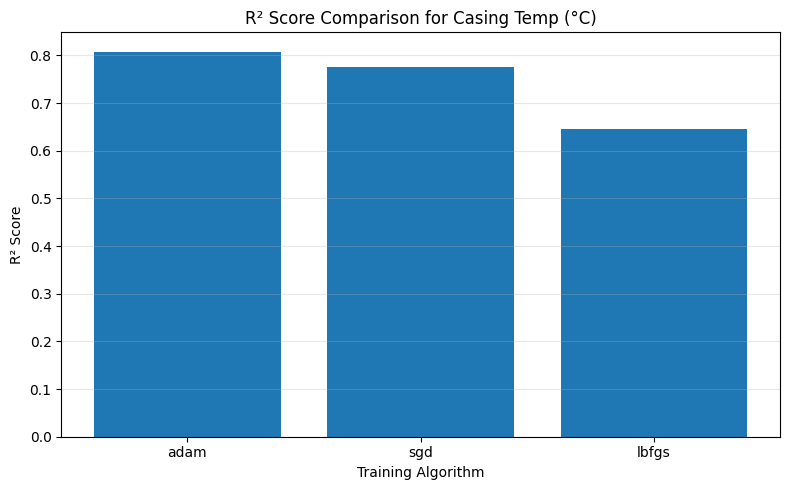

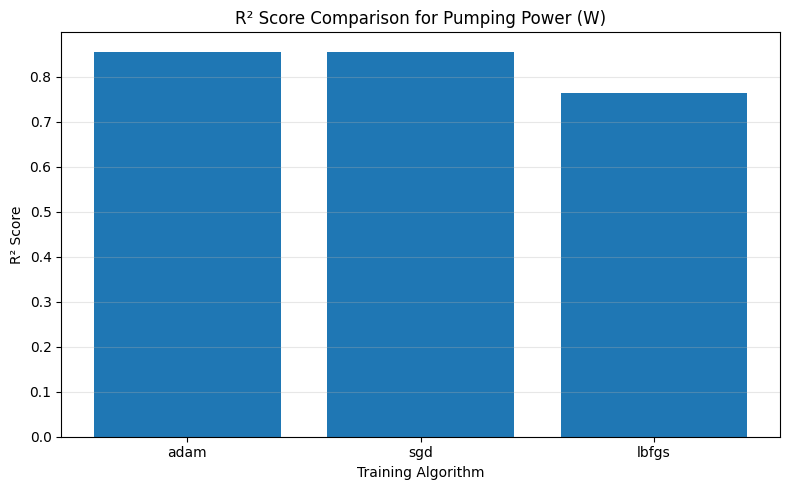

In [108]:
for target in algorithm_results["Target"].unique():

    data = algorithm_results[
        algorithm_results["Target"] == target
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        data["Training Algorithm"],
        data["R2 Score"]
    )

    plt.title(f"R² Score Comparison for {target}")
    plt.xlabel("Training Algorithm")
    plt.ylabel("R² Score")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [109]:
comparison = algorithm_results.pivot(
    index="Target",
    columns="Training Algorithm",
    values="RMSE"
)

display(comparison)

Training Algorithm,adam,lbfgs,sgd
Target,,,
Casing Temp (°C),3.679487,4.993134,3.972923
Cooling Efficiency (%),2.298490,2.837403,2.190985
Motor Efficiency (%),0.580475,0.759744,0.623098
Pumping Power (W),0.767563,0.983217,0.770521
Winding Temperature (°C),3.679487,4.993134,3.972923


Conclusion:
The experiment investigates the effect of three training algorithms, namely Adam, SGD, and L-BFGS, on ANN performance in predicting motor cooling system parameters. The algorithms are evaluated using RMSE, MAE, R² Score, and training time.
Feature and target scaling are applied to improve numerical stability during training. The evaluation metrics are calculated using predictions converted back to the original target units.
The results demonstrate how the choice of training algorithm affects prediction accuracy and computational time. The experimental results can be used to select an appropriate training algorithm for subsequent ANN experiments.

Experiment 5: Effect of Epochs on ANN Performance

To investigate the effect of different numbers of training epochs on the prediction performance of an Artificial Neural Network (ANN) for motor cooling system parameters.

In [110]:
epoch_values = [100, 500, 1000, 1500, 2000]

print("Epochs:", epoch_values)

Epochs: [100, 500, 1000, 1500, 2000]


In [111]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

epoch_results = []

for target in Y_train.columns:

    y_scaler = StandardScaler()

    y_train_scaled = y_scaler.fit_transform(
        Y_train[[target]]
    ).ravel()

    y_test = Y_test[target].values

    for epochs in epoch_values:

        model = MLPRegressor(
            hidden_layer_sizes=(32, 32),
            activation="relu",
            solver="adam",
            max_iter=epochs,
            learning_rate_init=0.001,
            tol=0,
            n_iter_no_change=epochs + 1,
            random_state=42
        )

        start_time = time.time()

        model.fit(X_train_scaled, y_train_scaled)

        training_time = time.time() - start_time

        predictions_scaled = model.predict(X_test_scaled)

        predictions = y_scaler.inverse_transform(
            predictions_scaled.reshape(-1, 1)
        ).ravel()

        rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )

        mae = mean_absolute_error(
            y_test, predictions
        )

        r2 = r2_score(
            y_test, predictions
        )

        epoch_results.append({
            "Target": target,
            "Epochs": epochs,
            "RMSE": rmse,
            "MAE": mae,
            "R2 Score": r2,
            "Training Time (s)": training_time,
            "Actual Iterations": model.n_iter_
        })

epoch_results = pd.DataFrame(epoch_results)

display(epoch_results)

,Target,Epochs,RMSE,MAE,R2 Score,Training Time (s),Actual Iterations
0,Winding Temperature (°C),100,3.678652,3.238886,0.807960,0.015059,100
1,Winding Temperature (°C),500,4.235212,3.801414,0.745455,0.061092,500
2,Winding Temperature (°C),1000,4.718093,4.224257,0.684101,0.119625,1000
3,Winding Temperature (°C),1500,4.819587,4.319186,0.670364,0.175216,1500
4,Winding Temperature (°C),2000,4.829843,4.328449,0.668960,0.230642,2000
5,Motor Efficiency (%),100,0.589439,0.515115,0.892704,0.012146,100
6,Motor Efficiency (%),500,0.702643,0.611364,0.847533,0.058668,500
7,Motor Efficiency (%),1000,0.743744,0.645570,0.829174,0.116330,1000
8,Motor Efficiency (%),1500,0.751809,0.651196,0.825449,0.174817,1500
9,Motor Efficiency (%),2000,0.753271,0.651631,0.824770,0.233030,2000


In [112]:
epoch_results.to_csv(
    "../experiments/results/epochs_results.csv",
    index=False
)

print("Epoch results saved successfully!")

Epoch results saved successfully!


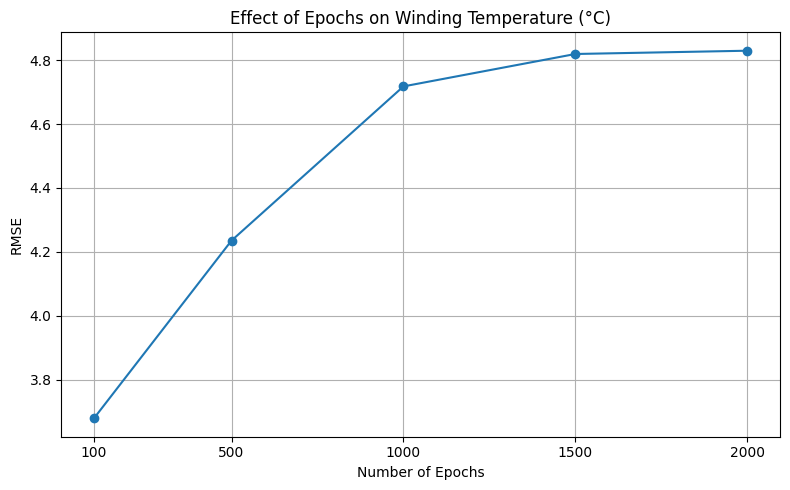

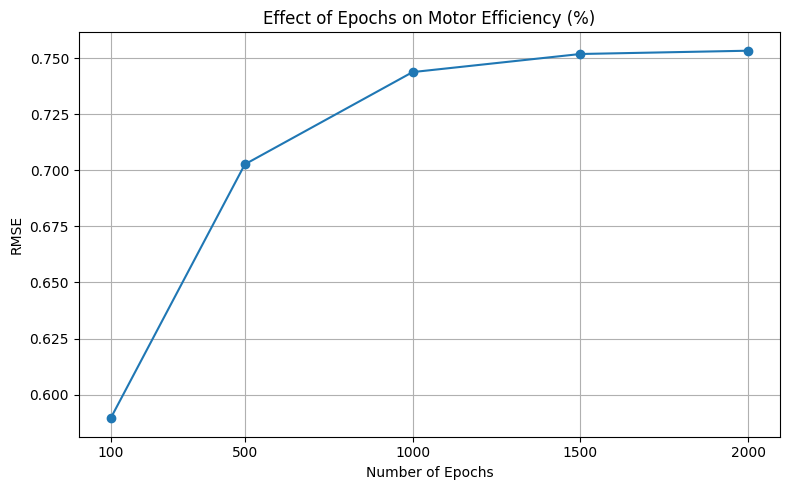

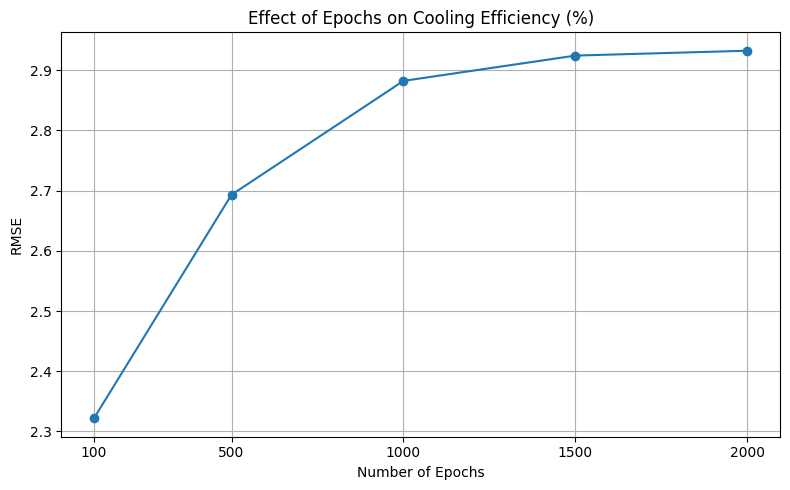

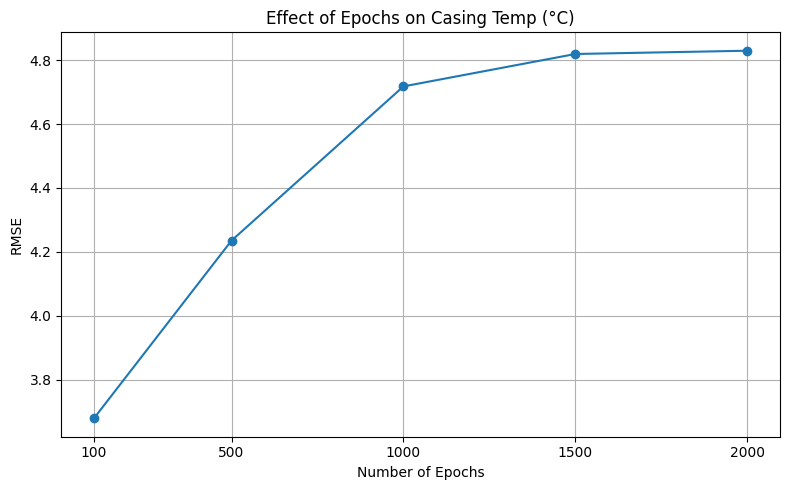

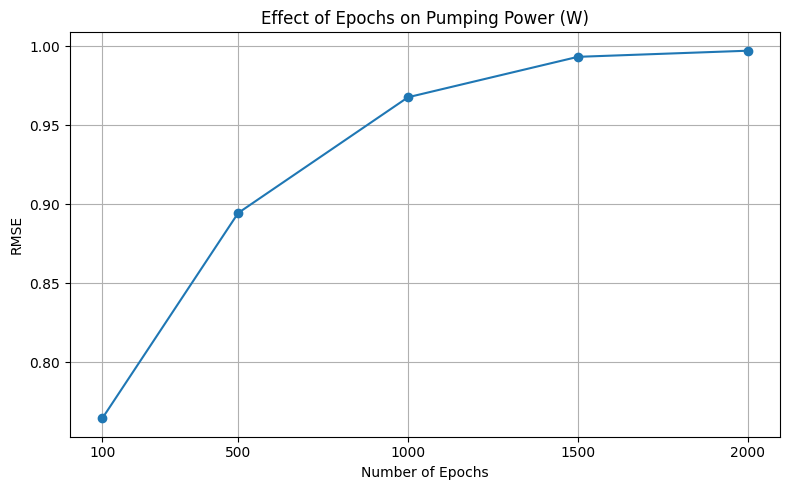

In [113]:
for target in epoch_results["Target"].unique():

    data = epoch_results[
        epoch_results["Target"] == target
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        data["Epochs"],
        data["RMSE"],
        marker="o"
    )

    plt.title(f"Effect of Epochs on {target}")
    plt.xlabel("Number of Epochs")
    plt.ylabel("RMSE")
    plt.xticks(epoch_values)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

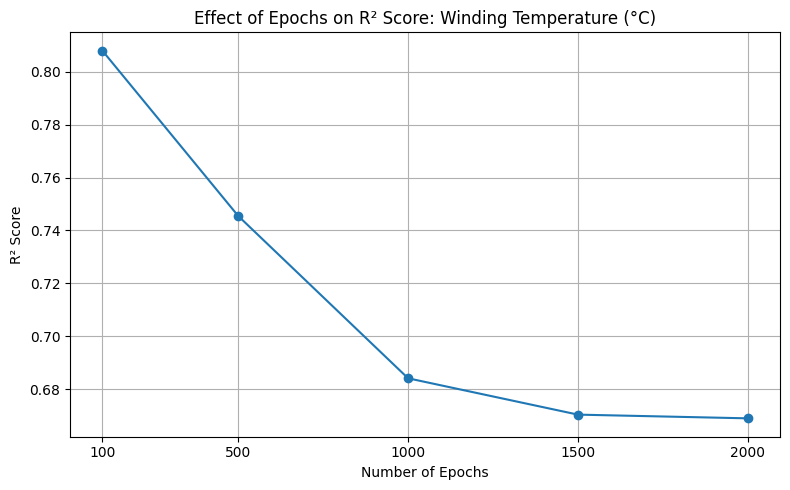

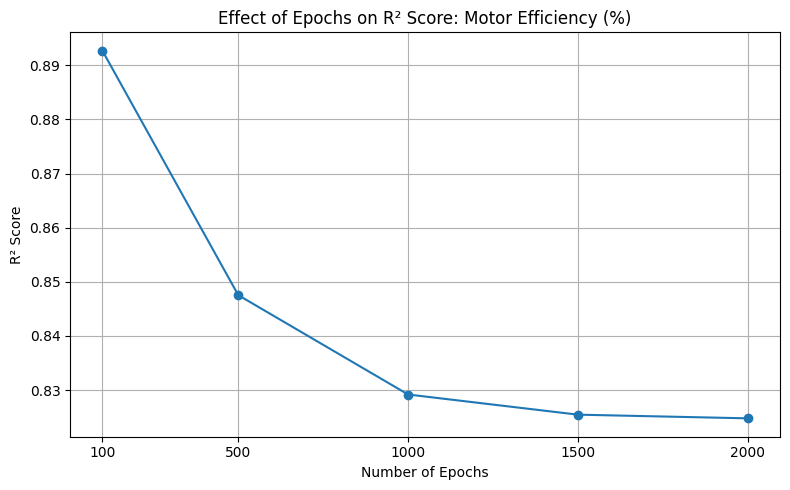

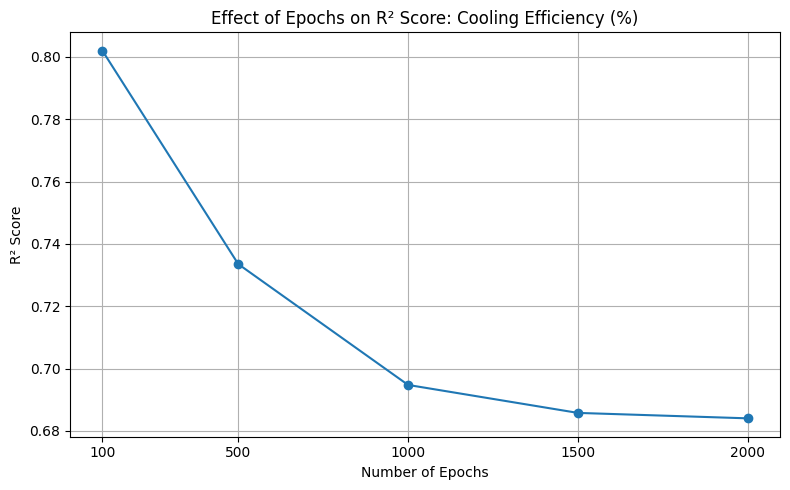

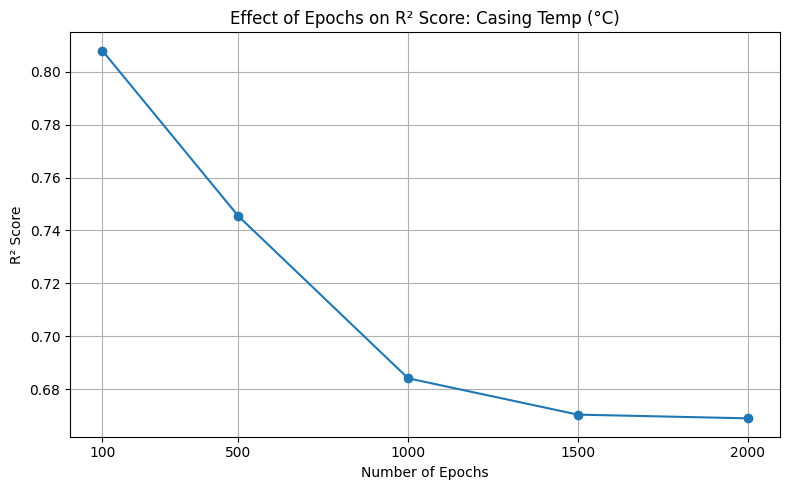

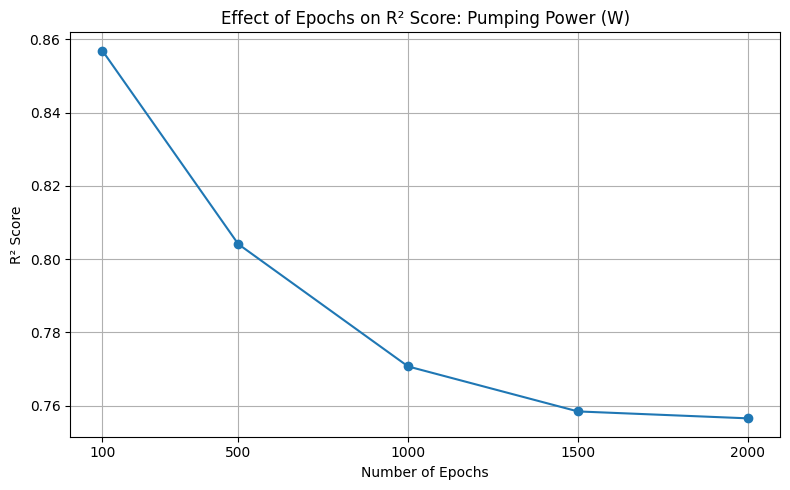

In [114]:
for target in epoch_results["Target"].unique():

    data = epoch_results[
        epoch_results["Target"] == target
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        data["Epochs"],
        data["R2 Score"],
        marker="o"
    )

    plt.title(f"Effect of Epochs on R² Score: {target}")
    plt.xlabel("Number of Epochs")
    plt.ylabel("R² Score")
    plt.xticks(epoch_values)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Conclution : The experiment investigates the effect of different numbers of training epochs on ANN performance. The models are evaluated using RMSE, MAE, R² Score, and training time. The results help illustrate how the number of training epochs affects prediction accuracy and computational cost.

# Experiment 6: Comparison of ANN Architectures

## Objective
To investigate the effect of different ANN architectures
on prediction performance by varying the number of
hidden layers and neurons.

## Architectures
1. Single hidden layer (16 neurons)
2. Single hidden layer (32 neurons)
3. Two hidden layers (32, 16 neurons)
4. Two hidden layers (64, 32 neurons)
5. Three hidden layers (64, 32, 16 neurons)

## Evaluation Metrics
- RMSE
- R² Score
- Training Time

In [115]:
%whos

Variable               Type              Data/Info
--------------------------------------------------
ConvergenceWarning     type              <class 'sklearn.exceptions.ConvergenceWarning'>
MLPRegressor           ABCMeta           <class 'sklearn.neural_ne<...>perceptron.MLPRegressor'>
Pipeline               ABCMeta           <class 'sklearn.pipeline.Pipeline'>
StandardScaler         type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                      DataFrame              Coolant Flow Rate (L<...>n\n[108 rows x 4 columns]
X_scaler               StandardScaler    StandardScaler()
X_test                 DataFrame              Coolant Flow Rate (L<...>    750              25  
X_test_scaled          ndarray           22x4: 88 elems, type `float64`, 704 bytes
X_tr                   ndarray           68x4: 272 elems, type `float64`, 2176 bytes
X_train                DataFrame              Coolant Flow Rate (L<...>\n\n[86 rows x 4 columns]
X_train_scaled       

Training input shape: (86, 4)
Validation input shape: (18, 4)
Training target shape: (86, 5)
Validation target shape: (18, 5)
Target names: ['Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)']

Training ANN_1: Hidden layers = (16,)
Training completed in 0.0390 seconds

Training ANN_2: Hidden layers = (32,)
Training completed in 0.0181 seconds

Training ANN_3: Hidden layers = (32, 16)
Training completed in 0.0208 seconds

Training ANN_4: Hidden layers = (64, 32)
Training completed in 0.0161 seconds

Training ANN_5: Hidden layers = (64, 32, 16)
Training completed in 0.0304 seconds

ANN ARCHITECTURE COMPARISON RESULTS


,Architecture,Hidden Layers,Target,RMSE,R2,Training Time (s)
0,ANN_1,"(16,)",Winding Temperature (°C),120.1775,-10921.1041,0.0390
1,ANN_1,"(16,)",Motor Efficiency (%),96.5040,-10214.2338,0.0390
2,ANN_1,"(16,)",Cooling Efficiency (%),80.7737,-6096.2562,0.0390
3,ANN_1,"(16,)",Casing Temp (°C),65.9892,-3292.1121,0.0390
4,ANN_1,"(16,)",Pumping Power (W),34.8741,-1174.5209,0.0390
5,ANN_2,"(32,)",Winding Temperature (°C),144.4369,-15775.7166,0.0181
6,ANN_2,"(32,)",Motor Efficiency (%),99.2006,-10793.1036,0.0181
7,ANN_2,"(32,)",Cooling Efficiency (%),91.1129,-7757.0931,0.0181
8,ANN_2,"(32,)",Casing Temp (°C),145.1377,-15929.1869,0.0181
9,ANN_2,"(32,)",Pumping Power (W),30.2741,-884.8632,0.0181



AVERAGE ARCHITECTURE PERFORMANCE


,Architecture,RMSE,R2,Training Time (s)
0,ANN_1,79.6637,-6339.6454,0.0390
1,ANN_2,102.0325,-10227.9927,0.0181
2,ANN_3,103.7299,-10123.8013,0.0208
3,ANN_4,97.0338,-9265.3636,0.0161
4,ANN_5,88.2426,-7778.0612,0.0304



Results saved successfully!


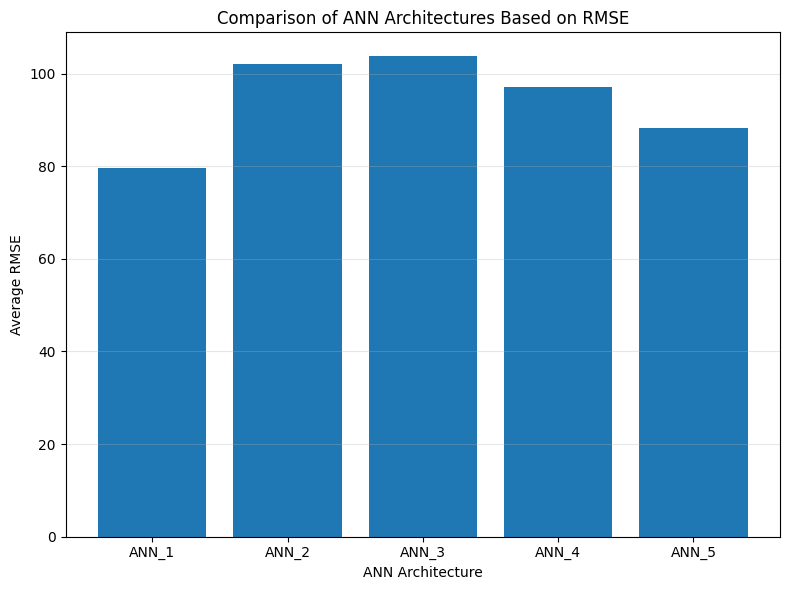

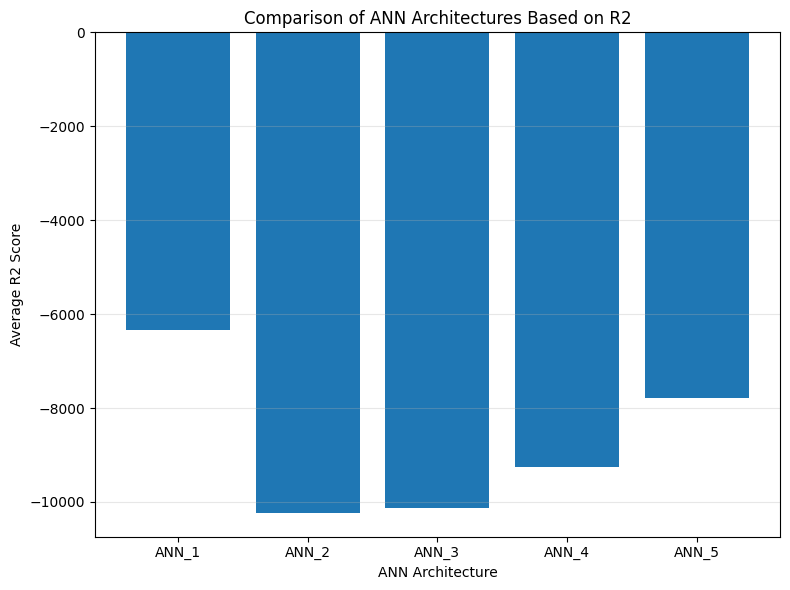

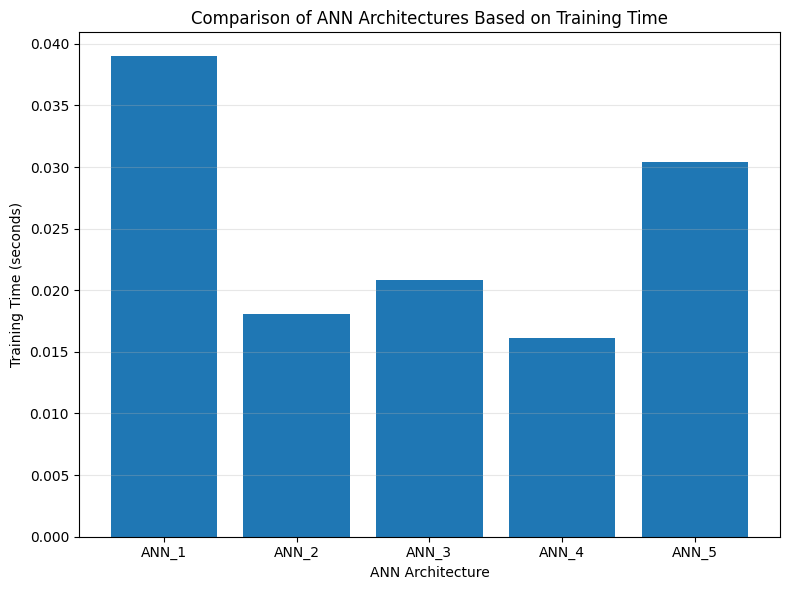


Experiment 6 completed successfully!

Saved files:
1. experiments/results/architecture_results.csv
2. experiments/results/architecture_average_results.csv
3. experiments/figures/architecture_rmse.png
4. experiments/figures/architecture_r2.png
5. experiments/figures/architecture_training_time.png


In [126]:
# ============================================================
# EXPERIMENT 6: COMPARISON OF ANN ARCHITECTURES
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. DEFINE ANN ARCHITECTURES
# ------------------------------------------------------------

architectures = {
    "ANN_1": (16,),
    "ANN_2": (32,),
    "ANN_3": (32, 16),
    "ANN_4": (64, 32),
    "ANN_5": (64, 32, 16)
}

# ------------------------------------------------------------
# 2. PREPARE TRAINING AND VALIDATION DATA
# ------------------------------------------------------------

X_train_exp = np.asarray(X_train_scaled, dtype=float)
X_val_exp = np.asarray(X_val_scaled, dtype=float)

Y_train_exp = np.asarray(Y_train, dtype=float)
Y_val_exp = np.asarray(Y_val, dtype=float)

# Ensure target arrays are 2D

if Y_train_exp.ndim == 1:
    Y_train_exp = Y_train_exp.reshape(-1, 1)

if Y_val_exp.ndim == 1:
    Y_val_exp = Y_val_exp.reshape(-1, 1)

# Check dimensions

assert X_train_exp.shape[0] == Y_train_exp.shape[0], \
    "Training input and target row counts do not match."

assert X_val_exp.shape[0] == Y_val_exp.shape[0], \
    "Validation input and target row counts do not match."

assert Y_train_exp.shape[1] == Y_val_exp.shape[1], \
    "Training and validation target counts do not match."

# Get target names

if isinstance(Y_train, pd.DataFrame):
    target_names = list(Y_train.columns)
elif isinstance(Y, pd.DataFrame):
    target_names = list(Y.columns)
else:
    target_names = [
        f"Target_{i+1}" for i in range(Y_train_exp.shape[1])
    ]

assert len(target_names) == Y_train_exp.shape[1], \
    "Number of target names does not match target columns."

print("Training input shape:", X_train_exp.shape)
print("Validation input shape:", X_val_exp.shape)
print("Training target shape:", Y_train_exp.shape)
print("Validation target shape:", Y_val_exp.shape)
print("Target names:", target_names)

# ------------------------------------------------------------
# 3. SCALE TARGET VARIABLES
# ------------------------------------------------------------

target_scaler_exp = StandardScaler()

Y_train_scaled_exp = target_scaler_exp.fit_transform(
    Y_train_exp
)

# ------------------------------------------------------------
# 4. TRAIN AND EVALUATE ANN ARCHITECTURES
# ------------------------------------------------------------

architecture_results = []

for name, layers in architectures.items():

    print(f"\nTraining {name}: Hidden layers = {layers}")

    model = MLPRegressor(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=42,
        tol=1e-4
    )

    # Measure training time
    start_time = time.time()

    model.fit(
        X_train_exp,
        Y_train_scaled_exp
    )

    training_time = time.time() - start_time

    # Predict validation data
    y_pred_scaled = model.predict(X_val_exp)

    # Ensure predictions are 2D
    y_pred_scaled = np.asarray(y_pred_scaled)

    if y_pred_scaled.ndim == 1:
        y_pred_scaled = y_pred_scaled.reshape(-1, 1)

    # Convert predictions to original scale
    y_pred = target_scaler_exp.inverse_transform(
        y_pred_scaled
    )

    # Calculate metrics for each target
    for i, target in enumerate(target_names):

        y_actual = Y_val_exp[:, i]
        y_pred_target = y_pred[:, i]

        rmse = np.sqrt(
            mean_squared_error(y_actual, y_pred_target)
        )

        r2 = r2_score(
            y_actual,
            y_pred_target
        )

        architecture_results.append({
            "Architecture": name,
            "Hidden Layers": str(layers),
            "Target": target,
            "RMSE": rmse,
            "R2": r2,
            "Training Time (s)": training_time
        })

    print(f"Training completed in {training_time:.4f} seconds")

# ------------------------------------------------------------
# 5. DISPLAY DETAILED RESULTS
# ------------------------------------------------------------

architecture_df = pd.DataFrame(architecture_results)

print("\nANN ARCHITECTURE COMPARISON RESULTS")

display(architecture_df.round(4))

# ------------------------------------------------------------
# 6. CALCULATE AVERAGE PERFORMANCE
# ------------------------------------------------------------

average_results = (
    architecture_df
    .groupby("Architecture", sort=False)
    .agg({
        "RMSE": "mean",
        "R2": "mean",
        "Training Time (s)": "first"
    })
    .reindex(architectures.keys())
    .reset_index()
)

print("\nAVERAGE ARCHITECTURE PERFORMANCE")

display(average_results.round(4))

# ------------------------------------------------------------
# 7. CREATE OUTPUT DIRECTORIES
# ------------------------------------------------------------

os.makedirs("experiments/results", exist_ok=True)
os.makedirs("experiments/figures", exist_ok=True)

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

architecture_df.to_csv(
    "experiments/results/architecture_results.csv",
    index=False
)

average_results.to_csv(
    "experiments/results/architecture_average_results.csv",
    index=False
)

print("\nResults saved successfully!")

# ------------------------------------------------------------
# 9. PLOT RMSE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.bar(
    average_results["Architecture"],
    average_results["RMSE"]
)

plt.xlabel("ANN Architecture")
plt.ylabel("Average RMSE")
plt.title("Comparison of ANN Architectures Based on RMSE")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "experiments/figures/architecture_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. PLOT R2 COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.bar(
    average_results["Architecture"],
    average_results["R2"]
)

plt.xlabel("ANN Architecture")
plt.ylabel("Average R2 Score")
plt.title("Comparison of ANN Architectures Based on R2")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "experiments/figures/architecture_r2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 11. PLOT TRAINING TIME COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.bar(
    average_results["Architecture"],
    average_results["Training Time (s)"]
)

plt.xlabel("ANN Architecture")
plt.ylabel("Training Time (seconds)")
plt.title("Comparison of ANN Architectures Based on Training Time")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "experiments/figures/architecture_training_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 12. COMPLETION MESSAGE
# ------------------------------------------------------------

print("\nExperiment 6 completed successfully!")

print("\nSaved files:")
print("1. experiments/results/architecture_results.csv")
print("2. experiments/results/architecture_average_results.csv")
print("3. experiments/figures/architecture_rmse.png")
print("4. experiments/figures/architecture_r2.png")
print("5. experiments/figures/architecture_training_time.png")

In [134]:
# ==========================================
# SAVE THE SELECTED ANN MODEL
# ==========================================

from pathlib import Path
import json
import joblib

# 1. Select the trained ANN model
best_model = model

# 2. Create the model directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# 3. Save the trained ANN model
model_path = model_dir / "best_ann_model.pkl"
joblib.dump(best_model, model_path)

# 4. Save the input and target scalers
joblib.dump(X_scaler, model_dir / "input_scaler.pkl")
joblib.dump(Y_scaler, model_dir / "target_scaler.pkl")

# 5. Save feature and target names
metadata = {
    "feature_names": list(X.columns),
    "target_names": list(Y.columns),
    "model_type": type(best_model).__name__
}

with open(model_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# 6. Verify saved files
print("=" * 50)
print("ANN MODEL SAVED SUCCESSFULLY")
print("=" * 50)

print("Model:", model_path)
print("Model type:", type(best_model).__name__)
print("Input scaler: Saved")
print("Target scaler: Saved")
print("Metadata: Saved")

print("\nSaved files:")
for file in sorted(model_dir.iterdir()):
    print("-", file.name)

ANN MODEL SAVED SUCCESSFULLY
Model: ../models/best_ann_model.pkl
Model type: MLPRegressor
Input scaler: Saved
Target scaler: Saved
Metadata: Saved

Saved files:
- best_ann_model.pkl
- input_scaler.pkl
- model_metadata.json
- target_scaler.pkl


In [135]:
# Check available scaler variables safely

print("Available scaler variables:")

for name, value in list(globals().items()):
    if "scal" in name.lower():
        print(name, type(value))

Available scaler variables:
StandardScaler <class 'type'>
X_scaler <class 'sklearn.preprocessing._data.StandardScaler'>
Y_scaler <class 'sklearn.preprocessing._data.StandardScaler'>
X_train_scaled <class 'numpy.ndarray'>
X_test_scaled <class 'numpy.ndarray'>
Y_train_scaled <class 'numpy.ndarray'>
Y_test_scaled <class 'numpy.ndarray'>
y_pred_scaled <class 'numpy.ndarray'>
pred_scaled <class 'numpy.ndarray'>
y_scaler <class 'sklearn.preprocessing._data.StandardScaler'>
y_train_scaled <class 'numpy.ndarray'>
predictions_scaled <class 'numpy.ndarray'>
X_val_scaled <class 'numpy.ndarray'>
y_scaler_arch <class 'sklearn.preprocessing._data.StandardScaler'>
y_train_arch_scaled <class 'numpy.ndarray'>
y_val_arch_scaled <class 'numpy.ndarray'>
architecture_scaler <class 'sklearn.preprocessing._data.StandardScaler'>
Y_train_scaled_exp <class 'numpy.ndarray'>
target_scaler_exp <class 'sklearn.preprocessing._data.StandardScaler'>
input_scaler <class 'NoneType'>
target_scaler <class 'NoneType'>


In [136]:
# Check preprocessing variables

print("Available preprocessing variables:")

for name in list(globals().keys()):
    if any(word in name.lower() for word in
           ["scaler", "standard", "normalizer", "transform"]):
        print(name)

Available preprocessing variables:
StandardScaler
X_scaler
Y_scaler
y_scaler
y_scaler_arch
architecture_scaler
target_scaler_exp
input_scaler
target_scaler
